In [1]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


[[194 193 191 ... 165 167 175]
 [194 193 192 ... 167 171 181]
 [194 193 192 ... 171 178 190]
 ...
 [182 154 146 ... 194 193 192]
 [187 162 148 ... 193 192 192]
 [189 177 154 ... 193 193 192]]


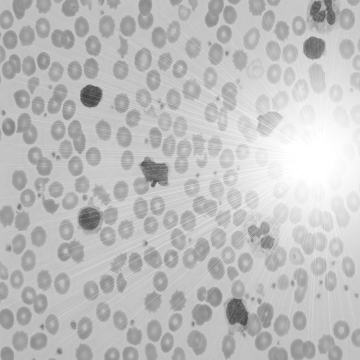

In [5]:
img = cv2.imread('/content/gdrive/My Drive/Colab26/Images/cell-bright.bmp')
RGB_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

gray_img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
gBin = np.zeros((RGB_img.shape[0], RGB_img.shape[1]), np.uint8)
print(gray_img)
cv2_imshow(gray_img)

In [22]:
N = 10

dimh = np.int32(gray_img.shape[0]/N)
dimw = np.int32(gray_img.shape[1]/N)
print(dimh,dimw)

resh = np.int32(gray_img.shape[0] % N)
resw = np.int32(gray_img.shape[1] % N)
print(resh,resw)

meanimg = np.zeros((N,N))
outimg = np.zeros((gray_img.shape[0], gray_img.shape[1]))

36 36
0 0


In [13]:
def mean_func(img, dimh, dimw, h, w):
  sum = np.int32(0)
  count = 0
  avg = 0

  for i in range(h, h + dimh):
    for j in range(w, w + dimw):
      sum += img[i,j]
      count += 1

  avg = np.int32(sum / count)
  return avg

In [23]:
for h in range(0, gray_img.shape[0] - resh, dimh):
  for w in range(0, gray_img.shape[1] - resw, dimw):
    meanimg[np.int32(h/dimh), np.int32(w/dimw)] = mean_func(gray_img, dimh, dimw, h, w)

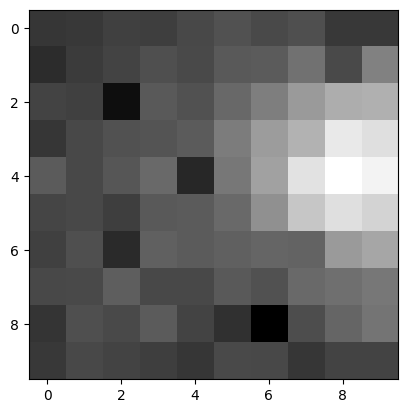

In [24]:
plt.imshow(meanimg, cmap='gray')

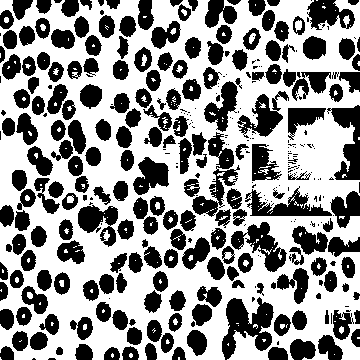

In [25]:
for h in range(0, gray_img.shape[0] - resh):
  for w in range(0, gray_img.shape[1] - resw):
    if(gray_img[h,w] > meanimg[np.int32(h/dimh), np.int32(w/dimw)]):
      outimg[h,w] = 255
    else:
      outimg[h,w] = 0

cv2_imshow(outimg)